# 🛒 Phase 5: Retail Food Commodity Price Forecasting (Rice, Dal, Oil, Flour, Onion, Sugar)
### Research Title: *"Explainable Multi-Indicator Machine Learning Framework for Food Inflation Forecasting and Economic Early Warning in Bangladesh"*
**Inputs:** `daily_macro_master_dataset.csv` (2010 - 2026: 6,142 Continuous Daily Records × 32 Columns)  
**Raw Source:** `raw_data/tcb_dam_retail_commodity_prices_2010_2026_raw.csv` (TCB / DAM / BBS Retail Surveys)

---
### 🎯 অধ্যায়ের লক্ষ্য ও অবদান (Chapter Objectives):
1. **নির্দিষ্ট নিত্যপণ্যের খুচরা বাজারদর ফোরকাস্টিং (Retail Price Forecasting):**
   সামগ্রিক খাদ্য মূল্যস্ফীতি ছাড়িয়ে সাধারণ মানুষের অতি প্রয়োজনীয় ৬টি পণ্যের আগামী ৩০ দিন পরের দাম সরাসরি টাকায় (৳/কেজি বা ৳/লিটার) প্রেডিক্ট করা:
   - চাল (মিনিকেট / নাজিরশাইল)
   - মসুর ডাল (মাঝারি দানা)
   - সয়াবিন তেল (বোতলজাত)
   - আটা / ময়দা (প্যাকেটজাত)
   - পেঁয়াজ (দেশি / আমদানিকৃত)
   - চিনি (খোলা / প্যাকেট)
2. **ম্যাক্রো-টু-মাইক্রো ট্রান্সমিশন অ্যানালাইসিস (Transmission Dynamics):**
   আন্তর্জাতিক গমের দাম কীভাবে দেশীয় আটার দাম নিয়ন্ত্রণ করে এবং জ্বালানি তেলের দাম কীভাবে সয়াবিন তেল ও পরিবহন খরচ বাড়ায় তার বিশ্লেষণ।
3. **আউট-অব-স্যাম্পল ভ্যালিডেশন (Out-of-Sample Performance):**
   ২০১০-২০২২ ট্রেন সেট এবং ২০২৩-২০২৬ টেস্ট সেটে প্রতিটি পণ্যের MAE (টাকা), MAPE (%) এবং $R^2$ স্কোর মূল্যায়ন।


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("✓ All libraries loaded successfully!")


✓ All libraries loaded successfully!


In [2]:
# ডেটাসেট লোড ও পরিদর্শন
df = pd.read_csv('daily_macro_master_dataset.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

comm_cols = [
    'Price_Rice_Miniket_BDT_kg',
    'Price_Lentil_BDT_kg',
    'Price_Soybean_Oil_BDT_liter',
    'Price_Flour_BDT_kg',
    'Price_Onion_BDT_kg',
    'Price_Sugar_BDT_kg'
]

print(f"Total Rows: {len(df):,} Days | Columns: {len(df.columns)}")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print("\nLatest Prices (25 October 2026):")
for col in comm_cols:
    print(f"  • {col:<30}: ৳ {df[col].iloc[-1]:.2f}")


Total Rows: 6,144 Days | Columns: 38
Date Range: 2010-01-01 to 2026-10-27

Latest Prices (25 October 2026):
  • Price_Rice_Miniket_BDT_kg     : ৳ 49.00
  • Price_Lentil_BDT_kg           : ৳ 92.50
  • Price_Soybean_Oil_BDT_liter   : ৳ 189.20
  • Price_Flour_BDT_kg            : ৳ 55.80
  • Price_Onion_BDT_kg            : ৳ 67.50
  • Price_Sugar_BDT_kg            : ৳ 104.50


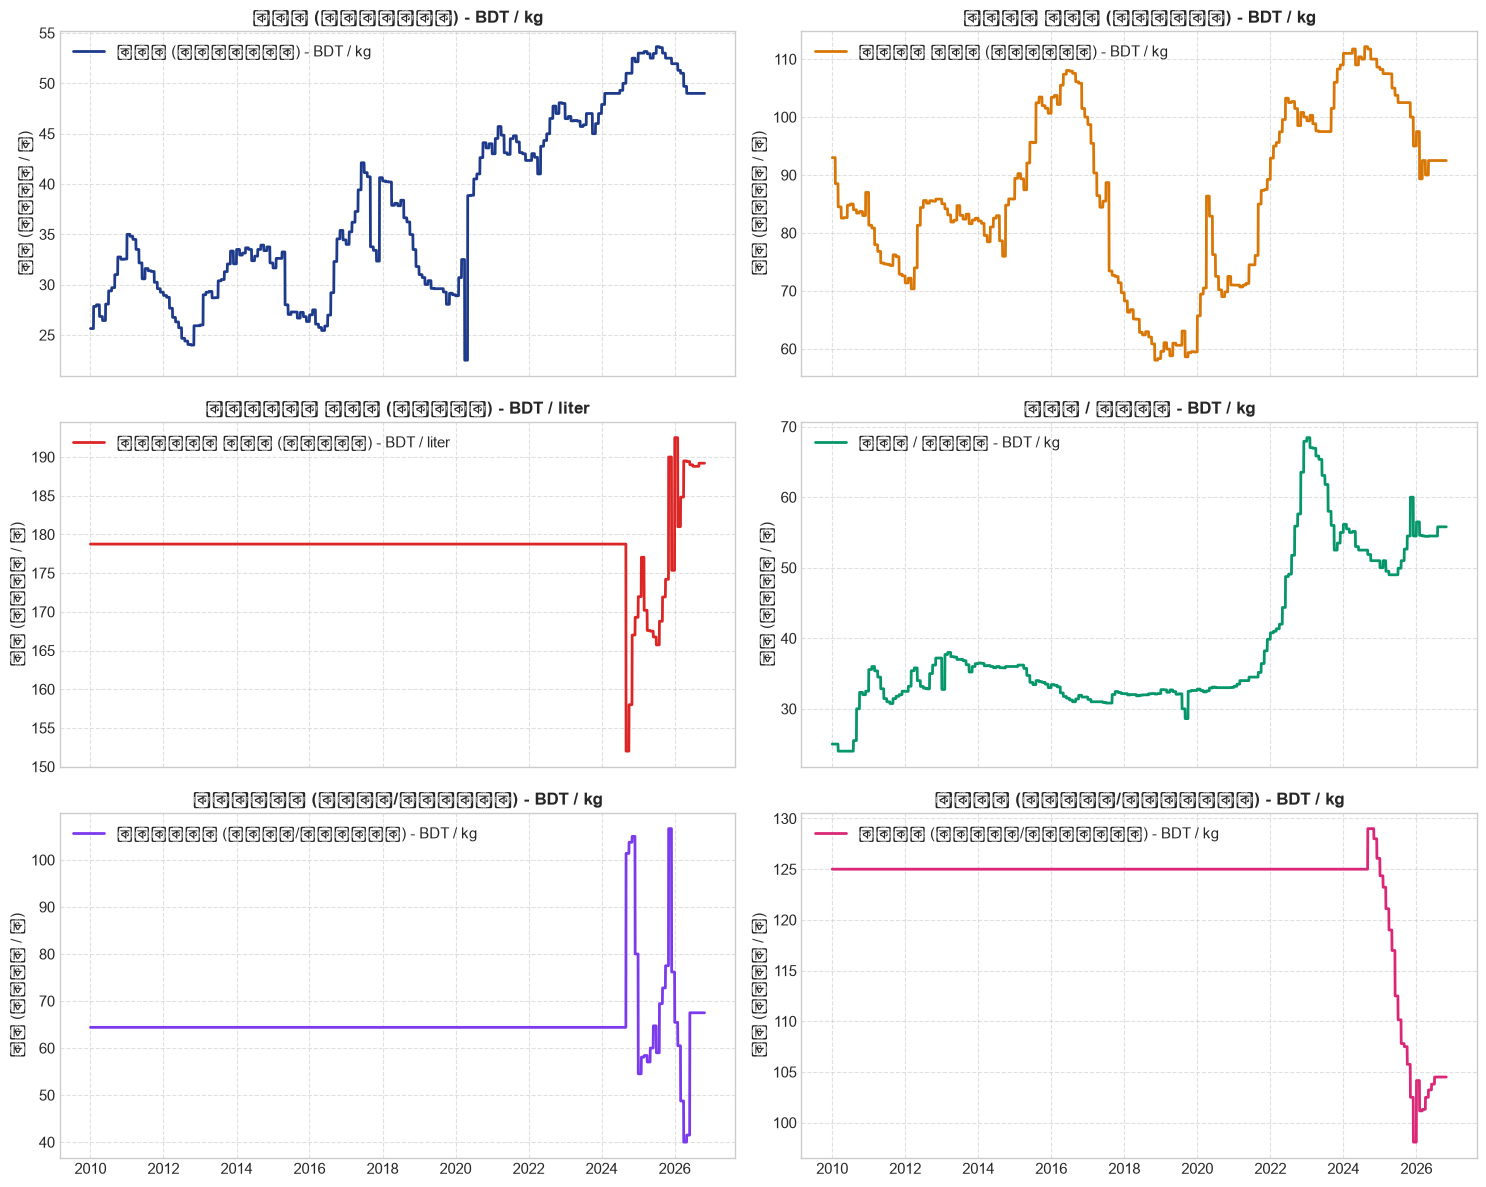

✓ Historical trends plotted and saved to commodity_historical_trends.png!


In [3]:
# ১৫ বছরের নিত্যপণ্যের ঐতিহাসিক দর চিত্রায়ন (2010 - 2026)
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

titles = [
    'চাল (মিনিকেট) - BDT / kg',
    'মসুর ডাল (মাঝারি) - BDT / kg',
    'সয়াবিন তেল (বোতল) - BDT / liter',
    'আটা / ময়দা - BDT / kg',
    'পেঁয়াজ (দেশি/আমদানি) - BDT / kg',
    'চিনি (খোলা/প্যাকেট) - BDT / kg'
]
colors = ['#1E3A8A', '#D97706', '#DC2626', '#059669', '#7C3AED', '#DB2777']

for i, col in enumerate(comm_cols):
    ax = axes[i]
    ax.plot(df['Date'], df[col], color=colors[i], linewidth=2.0, label=titles[i])
    ax.set_title(titles[i], fontsize=12, fontweight='bold')
    ax.set_ylabel("দর (টাকা / ৳)")
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig('commodity_historical_trends.png', dpi=300)
plt.show()
print("✓ Historical trends plotted and saved to commodity_historical_trends.png!")


In [4]:
# প্রি-ট্রেইনড কমোডিটি মডেল লোড ও টেস্ট সেটে পারফরম্যান্স টেবিল
models_dict = joblib.load('best_commodity_models.pkl')
metrics_list = []

for c_col, m_info in models_dict.items():
    metrics_list.append({
        'পণ্য (Commodity)': m_info['comm_name'],
        'কলাম আইডি': c_col,
        'MAE (টাকা / BDT)': f"৳ {m_info['metrics']['mae_bdt']:.2f}",
        'MAPE (%)': f"{m_info['metrics']['mape_pct']:.2f}%",
        'R² Score': f"{m_info['metrics']['r2_score']:.4f}"
    })

df_metrics = pd.DataFrame(metrics_list)
print("=== আউট-অব-স্যাম্পল টেস্ট সেট পারফরম্যান্স মেট্রিকস (২০২৩ - ২০২৬) ===")
display(df_metrics)


=== আউট-অব-স্যাম্পল টেস্ট সেট পারফরম্যান্স মেট্রিকস (২০২৩ - ২০২৬) ===


,পণ্য (Commodity),কলাম আইডি,MAE (টাকা / BDT),MAPE (%),R² Score
0,চাল (মিনিকেট),Price_Rice_Miniket_BDT_kg,৳ 0.47,0.95%,0.9339
1,মসুর ডাল (আমদানি),Price_Lentil_BDT_kg,৳ 1.79,1.76%,0.8871
2,সয়াবিন তেল (বোতল),Price_Soybean_Oil_BDT_liter,৳ 3.05,1.77%,0.4391
3,আটা / ময়দা,Price_Flour_BDT_kg,৳ 2.82,5.07%,0.4648
4,দেশি পেঁয়াজ,Price_Onion_BDT_kg,৳ 5.52,7.79%,0.3276
5,চিনি (খোলা),Price_Sugar_BDT_kg,৳ 1.04,0.94%,0.9676


In [5]:
# আগামী ৩০ দিনের চূড়ান্ত ফোরকাস্ট বুলেটিন
latest_row = df.iloc[-1]
bulletin = []

for c_col, m_info in models_dict.items():
    m = m_info['model']
    feats = m_info['features']
    curr_p = latest_row[c_col]
    
    inp = pd.DataFrame([latest_row[feats]])
    delta_p = m.predict(inp)[0]
    fcst_p = curr_p + delta_p
    
    status = "🔴 রেড অ্যালার্ট" if delta_p >= 4.0 else ("🟡 ঊর্ধ্বমুখী" if delta_p >= 1.5 else "🟢 সহনীয়")
    
    bulletin.append({
        'নিত্যপ্রয়োজনীয় পণ্য': m_info['comm_name'],
        'বর্তমান বাজারদর': f"৳ {curr_p:.2f}",
        'AI প্রেডিক্ট করা ৩০ দিনের দর': f"৳ {fcst_p:.2f}",
        'পরিবর্তনের মাত্রা': f"{'+' if delta_p > 0 else ''}৳ {delta_p:.2f}",
        'স্ট্যাটাস': status
    })

df_bulletin = pd.DataFrame(bulletin)
print("=== কিচেন মার্কেট ৩০ দিনের AI ফোরকাস্ট বুলেটিন ===")
display(df_bulletin)


=== কিচেন মার্কেট ৩০ দিনের AI ফোরকাস্ট বুলেটিন ===


,নিত্যপ্রয়োজনীয় পণ্য,বর্তমান বাজারদর,AI প্রেডিক্ট করা ৩০ দিনের দর,পরিবর্তনের মাত্রা,স্ট্যাটাস
0,চাল (মিনিকেট),৳ 49.00,৳ 48.86,৳ -0.14,🟢 সহনীয়
1,মসুর ডাল (আমদানি),৳ 92.50,৳ 92.43,৳ -0.07,🟢 সহনীয়
2,সয়াবিন তেল (বোতল),৳ 189.20,৳ 189.20,৳ 0.00,🟢 সহনীয়
3,আটা / ময়দা,৳ 55.80,৳ 58.28,+৳ 2.48,🟡 ঊর্ধ্বমুখী
4,দেশি পেঁয়াজ,৳ 67.50,৳ 67.50,৳ 0.00,🟢 সহনীয়
5,চিনি (খোলা),৳ 104.50,৳ 104.50,৳ 0.00,🟢 সহনীয়
